# Natural Component Alignment Summary

Load cached `natural_component_align` summaries and visualize component-wise best-layer and layer-wise alignment patterns.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'natural_component_align').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from natural_component_align.cache_summary import COMPILED_ROOT, DEFAULT_OUTPUT_ROOT, write_compiled_summaries
from natural_component_align.pipeline import DEFAULT_MODELS

MODEL_ORDER = list(DEFAULT_MODELS)
COMPONENT_ORDER = ['lowfreq', 'highfreq', 'envsounds', 'pitch', 'speech', 'music']
REG_METRIC = 'mean_r2'
RSA_METRIC = 'mean_spearman'

MODEL_COLORS = {
    model: plt.get_cmap('tab20')(i / max(1, len(MODEL_ORDER) - 1))
    for i, model in enumerate(MODEL_ORDER)
}
COMPONENT_COLORS = {
    component: plt.get_cmap('tab10')(i / max(1, len(COMPONENT_ORDER) - 1))
    for i, component in enumerate(COMPONENT_ORDER)
}

def refresh_component_summaries(output_root=DEFAULT_OUTPUT_ROOT, compiled_root=COMPILED_ROOT):
    reg_pkl, rsa_pkl = write_compiled_summaries(output_root=output_root, compiled_root=compiled_root)
    regression_all = pd.read_pickle(reg_pkl)
    rsa_all = pd.read_pickle(rsa_pkl)
    return regression_all, rsa_all

def ordered_present_models(frame):
    present = set(frame['model_name'].astype(str).unique())
    return [model for model in MODEL_ORDER if model in present]

def best_by_model_and_component(frame, metric_column):
    return (
        frame.sort_values(metric_column, ascending=False)
        .groupby(['model_name', 'component_name'], as_index=False)
        .head(1)
        .reset_index(drop=True)
    )

def add_relative_layer_position(frame):
    frame = frame.copy()
    max_depth = frame.groupby('model_name')['layer_depth'].transform('max').replace(0, 1)
    frame['relative_layer_position'] = frame['layer_depth'] / max_depth
    return frame

def plot_best_alignment_panels(regression_all, rsa_all):
    reg_best = best_by_model_and_component(regression_all, REG_METRIC)
    rsa_best = best_by_model_and_component(rsa_all, RSA_METRIC)

    fig, axes = plt.subplots(6, 2, figsize=(18, 24), constrained_layout=True)
    metric_specs = [
        ('Regression', reg_best, REG_METRIC, 'Best raw explained variance ($R^2$)'),
        ('RSA', rsa_best, RSA_METRIC, 'Best Spearman RSA'),
    ]

    for row_index, component_name in enumerate(COMPONENT_ORDER):
        for col_index, (title, table, metric_column, y_label) in enumerate(metric_specs):
            ax = axes[row_index, col_index]
            subset = table.loc[table['component_name'] == component_name].copy()
            if subset.empty:
                ax.set_axis_off()
                continue
            subset = subset.sort_values(metric_column, ascending=False)
            x_labels = subset['model_name'].tolist()
            x = np.arange(len(x_labels))
            colors = [MODEL_COLORS.get(model, '#4C72B0') for model in x_labels]
            ax.bar(x, subset[metric_column].to_numpy(), color=colors)
            ax.set_xticks(x)
            ax.set_xticklabels(x_labels, rotation=60, ha='right')
            ax.set_ylabel(y_label)
            if row_index == 0:
                ax.set_title(title, fontsize=13, fontweight='bold')
            ax.text(0.01, 0.95, component_name, transform=ax.transAxes, ha='left', va='top', fontsize=11, fontweight='bold')
            ax.grid(axis='y', alpha=0.2)

    return fig, axes

def plot_component_layerwise_all_models(regression_all, rsa_all, component_name='speech'):
    component_name = component_name.strip().lower()
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True, sharex=False)
    metric_specs = [
        ('Regression', regression_all, REG_METRIC, 'Layer-wise raw explained variance ($R^2$)'),
        ('RSA', rsa_all, RSA_METRIC, 'Layer-wise Spearman RSA'),
    ]

    for ax, (title, table, metric_column, y_label) in zip(axes, metric_specs):
        subset = table.loc[table['component_name'].str.lower() == component_name].copy()
        subset = add_relative_layer_position(subset)
        models = ordered_present_models(subset)
        for model_name in models:
            model_df = subset.loc[subset['model_name'] == model_name].sort_values('layer_depth')
            if model_df.empty:
                continue
            ax.plot(
                model_df['relative_layer_position'],
                model_df[metric_column],
                marker='o',
                markersize=3,
                linewidth=1.6,
                color=MODEL_COLORS.get(model_name, '#4C72B0'),
                label=model_name,
                alpha=0.95,
            )
            final_df = model_df.loc[model_df['is_final'].astype(bool)]
            if not final_df.empty:
                ax.scatter(
                    final_df['relative_layer_position'],
                    final_df[metric_column],
                    color=MODEL_COLORS.get(model_name, '#4C72B0'),
                    s=35,
                    edgecolor='black',
                    linewidth=0.4,
                    zorder=4,
                )
        ax.set_title(f'{title}: {component_name}', fontsize=13, fontweight='bold')
        ax.set_xlabel('Relative layer position')
        ax.set_ylabel(y_label)
        ax.set_xlim(-0.02, 1.02)
        ax.set_xticks(np.linspace(0, 1, 6))
        ax.set_xticklabels([f'{int(100 * tick)}%' for tick in np.linspace(0, 1, 6)])
        ax.grid(alpha=0.2)

    handles, labels = axes[-1].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
    return fig, axes

def plot_model_layerwise_all_components(regression_all, rsa_all, model_name='MERT'):
    model_name = model_name.strip().upper()
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True, sharex=False)
    metric_specs = [
        ('Regression', regression_all, REG_METRIC, 'Layer-wise raw explained variance ($R^2$)'),
        ('RSA', rsa_all, RSA_METRIC, 'Layer-wise Spearman RSA'),
    ]

    for ax, (title, table, metric_column, y_label) in zip(axes, metric_specs):
        subset = table.loc[table['model_name'].str.upper() == model_name].copy()
        subset = add_relative_layer_position(subset)
        for component_name in COMPONENT_ORDER:
            component_df = subset.loc[subset['component_name'].str.lower() == component_name].sort_values('layer_depth')
            if component_df.empty:
                continue
            ax.plot(
                component_df['relative_layer_position'],
                component_df[metric_column],
                marker='o',
                markersize=3,
                linewidth=1.8,
                color=COMPONENT_COLORS[component_name],
                label=component_name,
                alpha=0.95,
            )
            final_df = component_df.loc[component_df['is_final'].astype(bool)]
            if not final_df.empty:
                ax.scatter(
                    final_df['relative_layer_position'],
                    final_df[metric_column],
                    color=COMPONENT_COLORS[component_name],
                    s=35,
                    edgecolor='black',
                    linewidth=0.4,
                    zorder=4,
                )
        ax.set_title(f'{title}: {model_name}', fontsize=13, fontweight='bold')
        ax.set_xlabel('Relative layer position')
        ax.set_ylabel(y_label)
        ax.set_xlim(-0.02, 1.02)
        ax.set_xticks(np.linspace(0, 1, 6))
        ax.set_xticklabels([f'{int(100 * tick)}%' for tick in np.linspace(0, 1, 6)])
        ax.grid(alpha=0.2)

    handles, labels = axes[-1].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
    return fig, axes

regression_all, rsa_all = refresh_component_summaries()
print(f'Regression rows: {len(regression_all)}')
print(f'RSA rows: {len(rsa_all)}')
display(regression_all.head())


Regression rows: 1572
RSA rows: 1572


,model_name,representation_name,layer_index,component_name,mean_r2,median_r2,mean_train_r2,median_train_r2,mean_alpha,median_alpha,n_splits,source_dim,layer_depth,is_final,result_dir
0,CLAP,final,NaN,lowfreq,0.732778,0.733706,0.992950,0.997568,17.0,10.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
1,CLAP,final,NaN,highfreq,0.578873,0.579190,0.956974,0.961021,55.0,55.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
2,CLAP,final,NaN,envsounds,0.531932,0.526833,0.938374,0.919155,72.0,100.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
3,CLAP,final,NaN,pitch,0.756233,0.748336,0.997979,0.997404,7.1,10.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...
4,CLAP,final,NaN,speech,0.836313,0.845660,0.997826,0.997616,9.0,10.0,10,768,5,True,/home/hjkim/selective_auditory/ismir2026/natur...


## 1. Best Alignment By Model

Each row is a component, each column is `regression` / `rsa`. Bars are sorted in descending order within each panel.

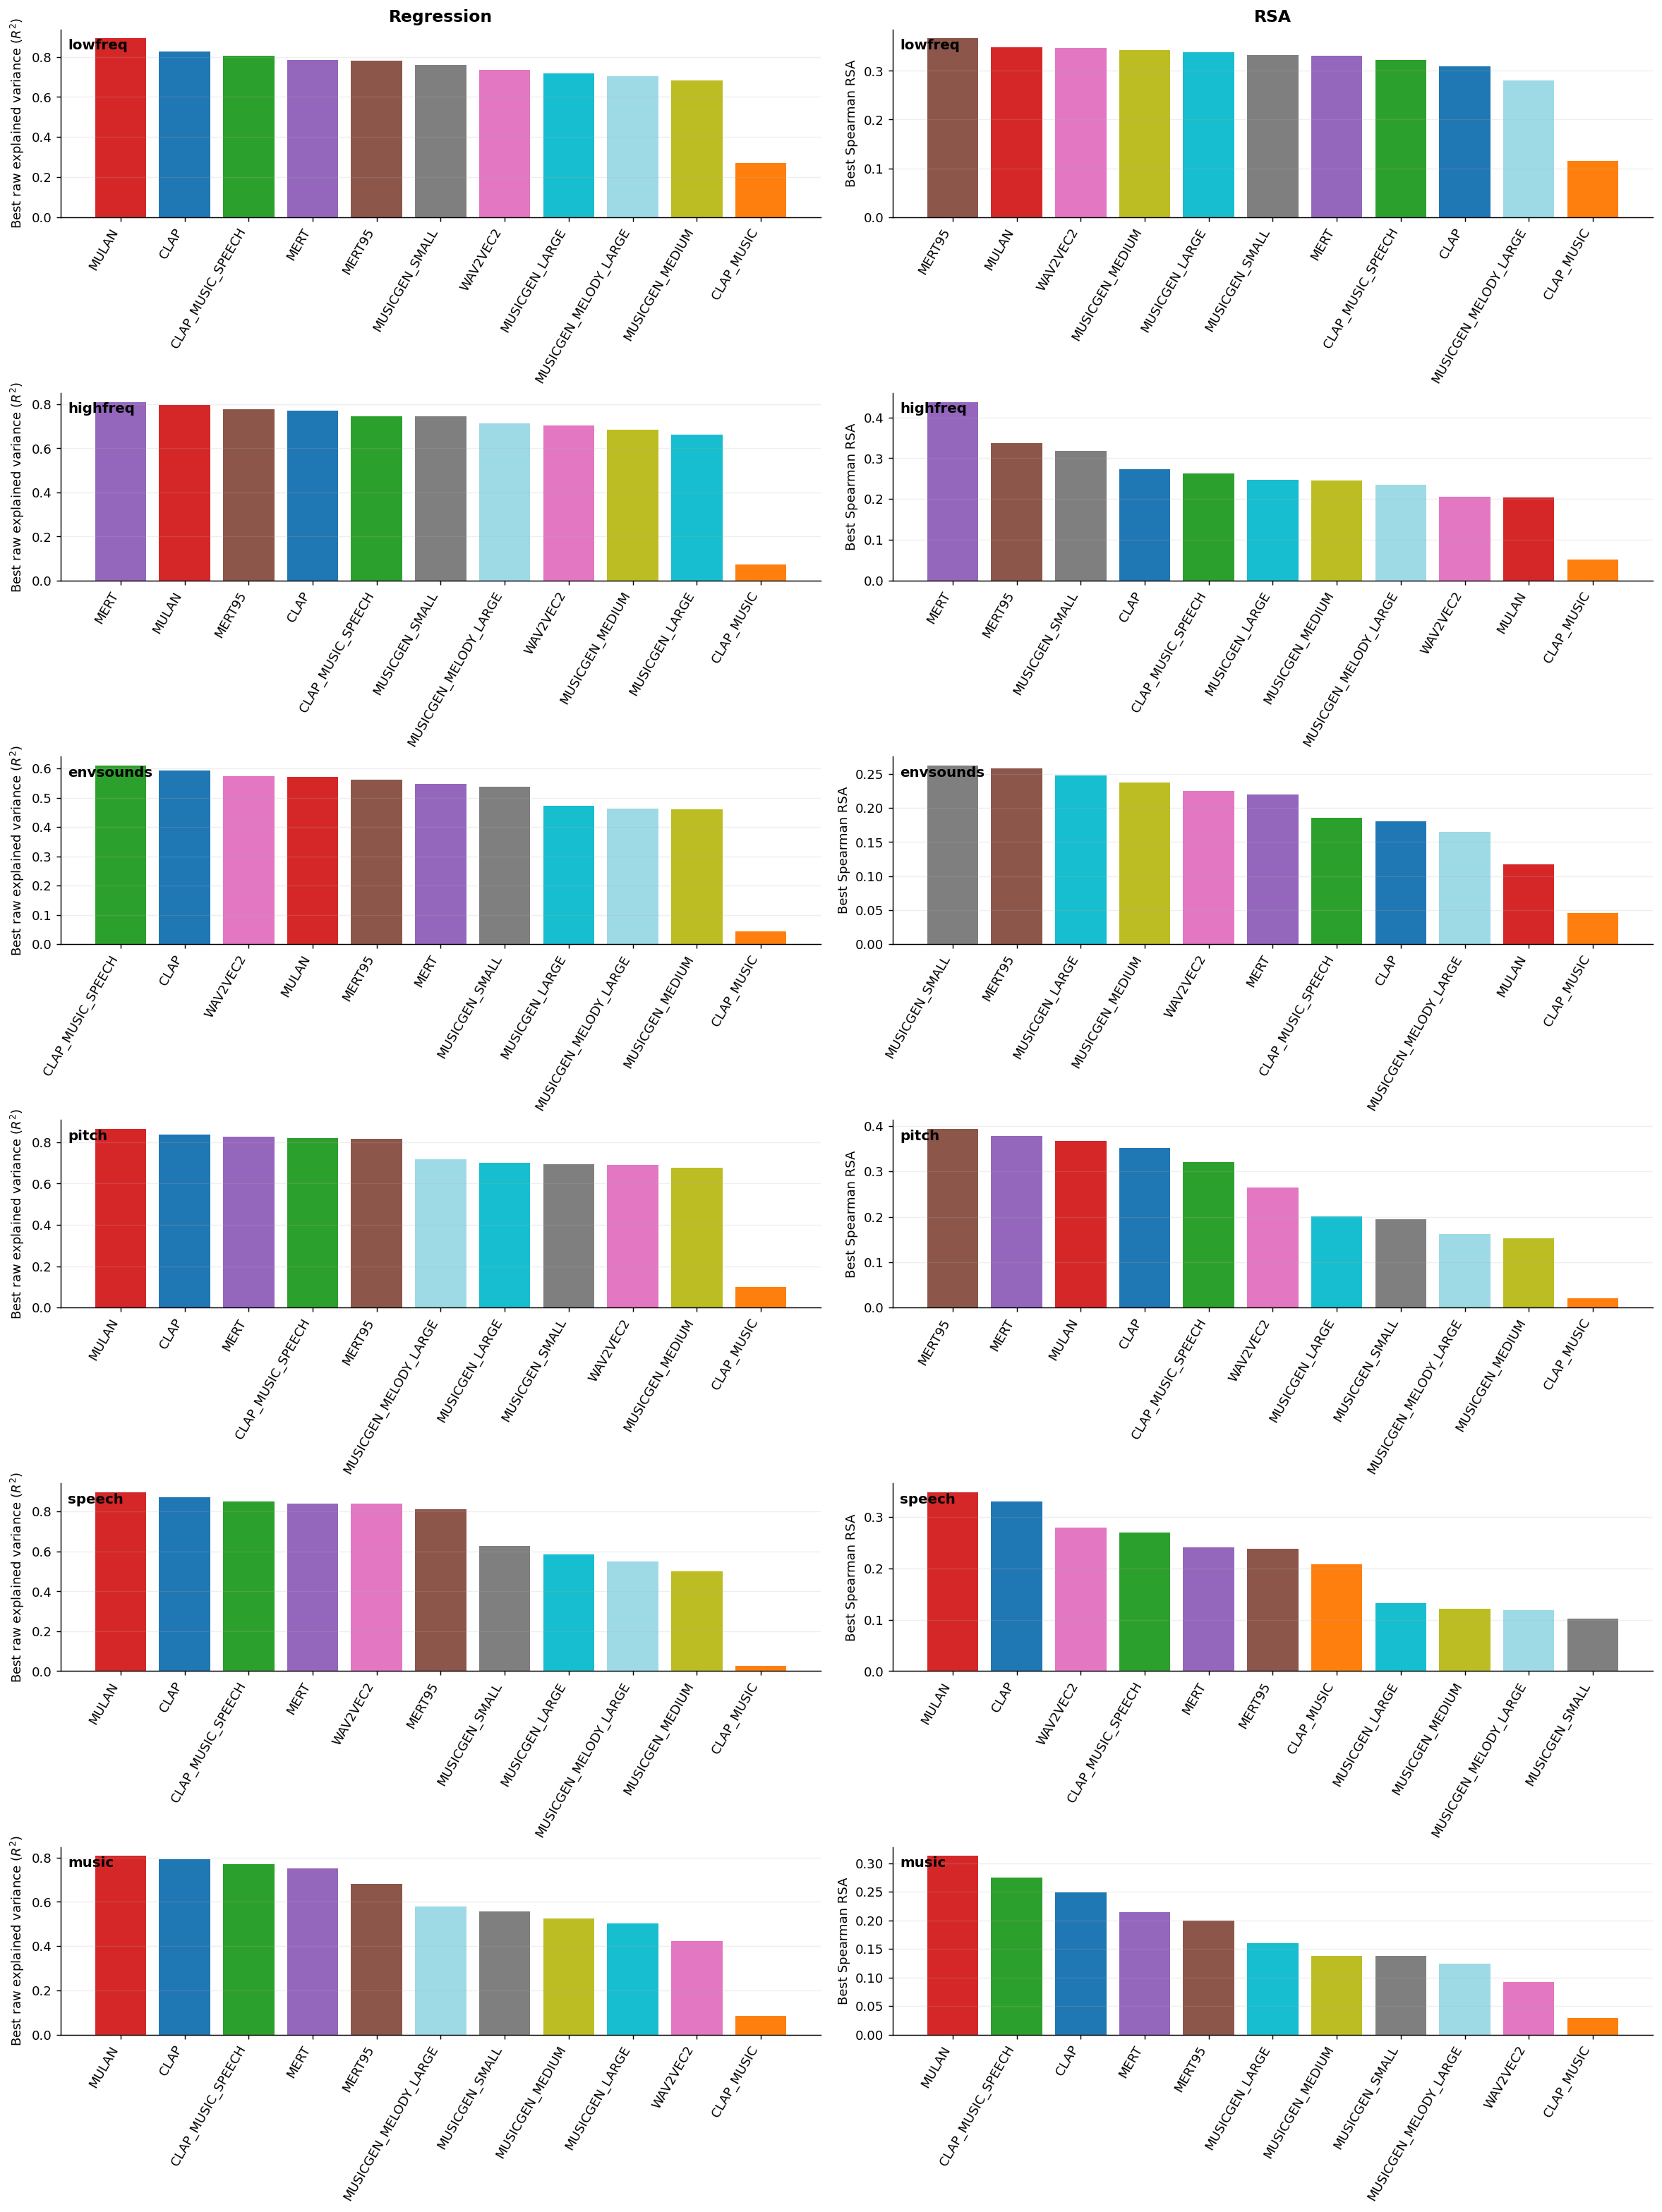

In [2]:
regression_all, rsa_all = refresh_component_summaries()
fig, axes = plot_best_alignment_panels(regression_all, rsa_all)
plt.show()

## 2. One Component Across All Models

Change `component_name` and rerun the cell.

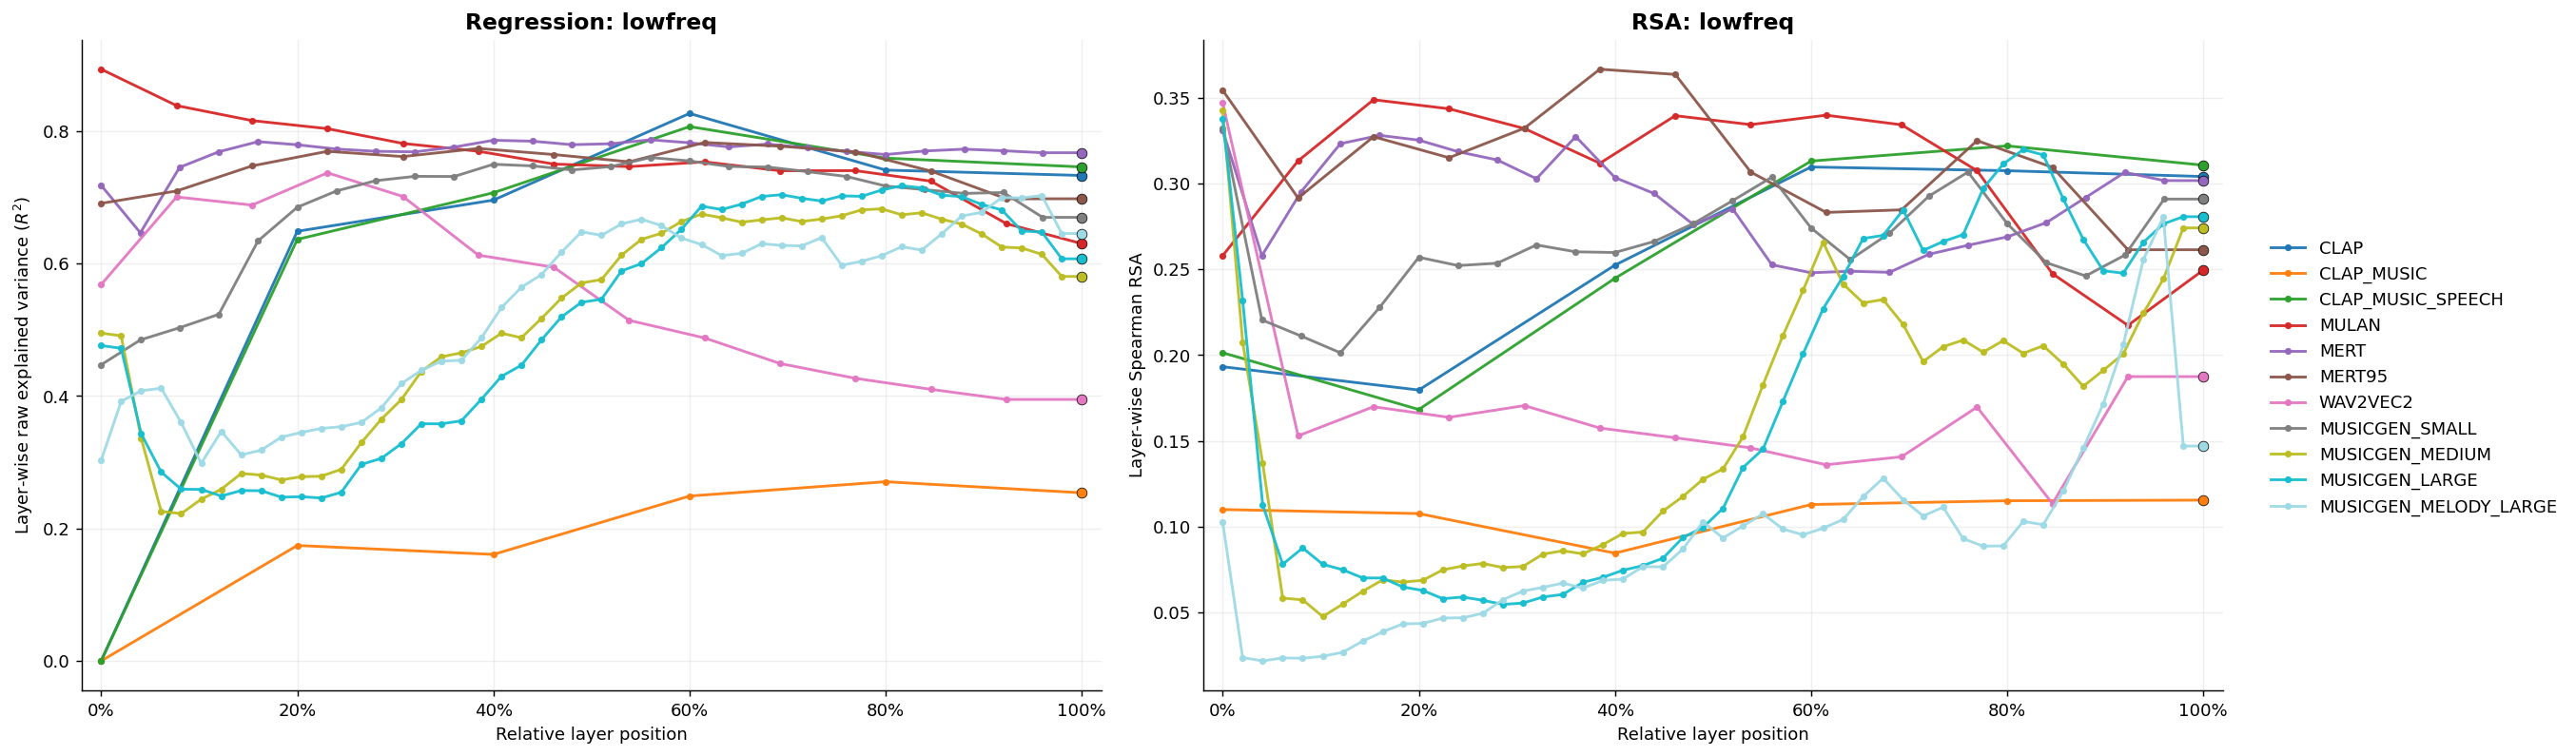

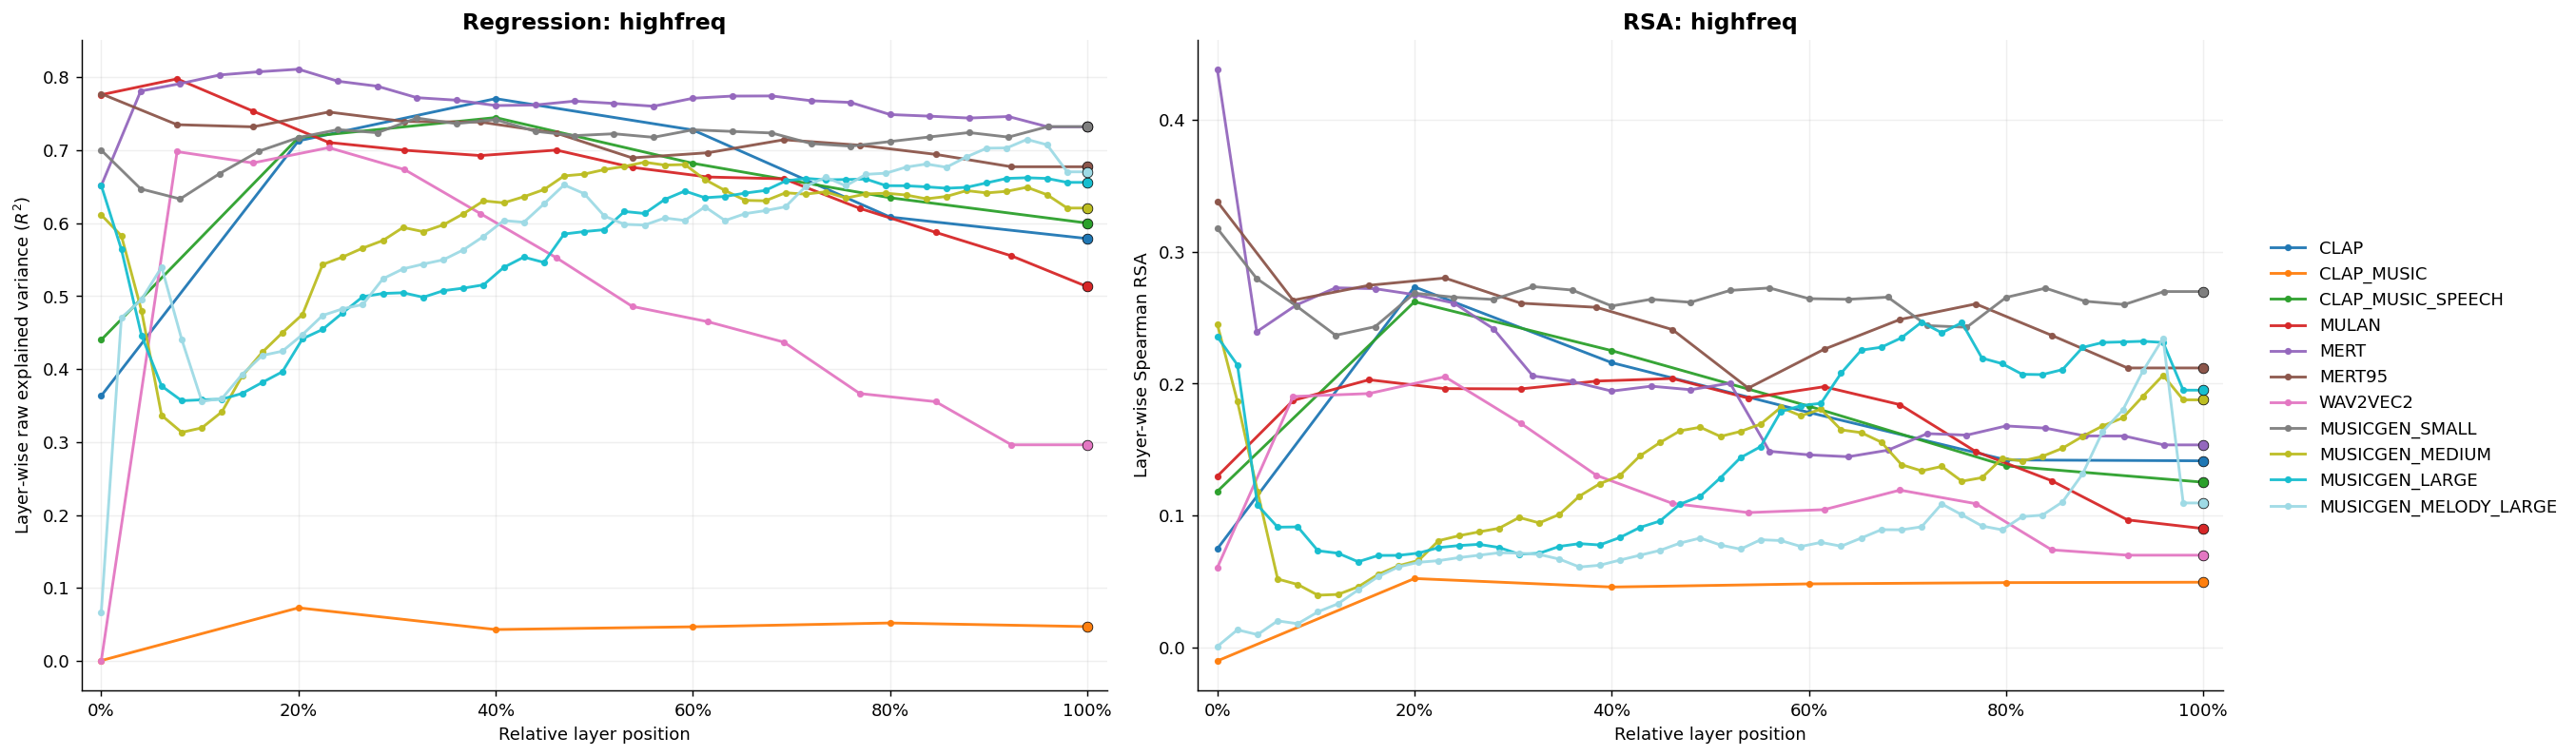

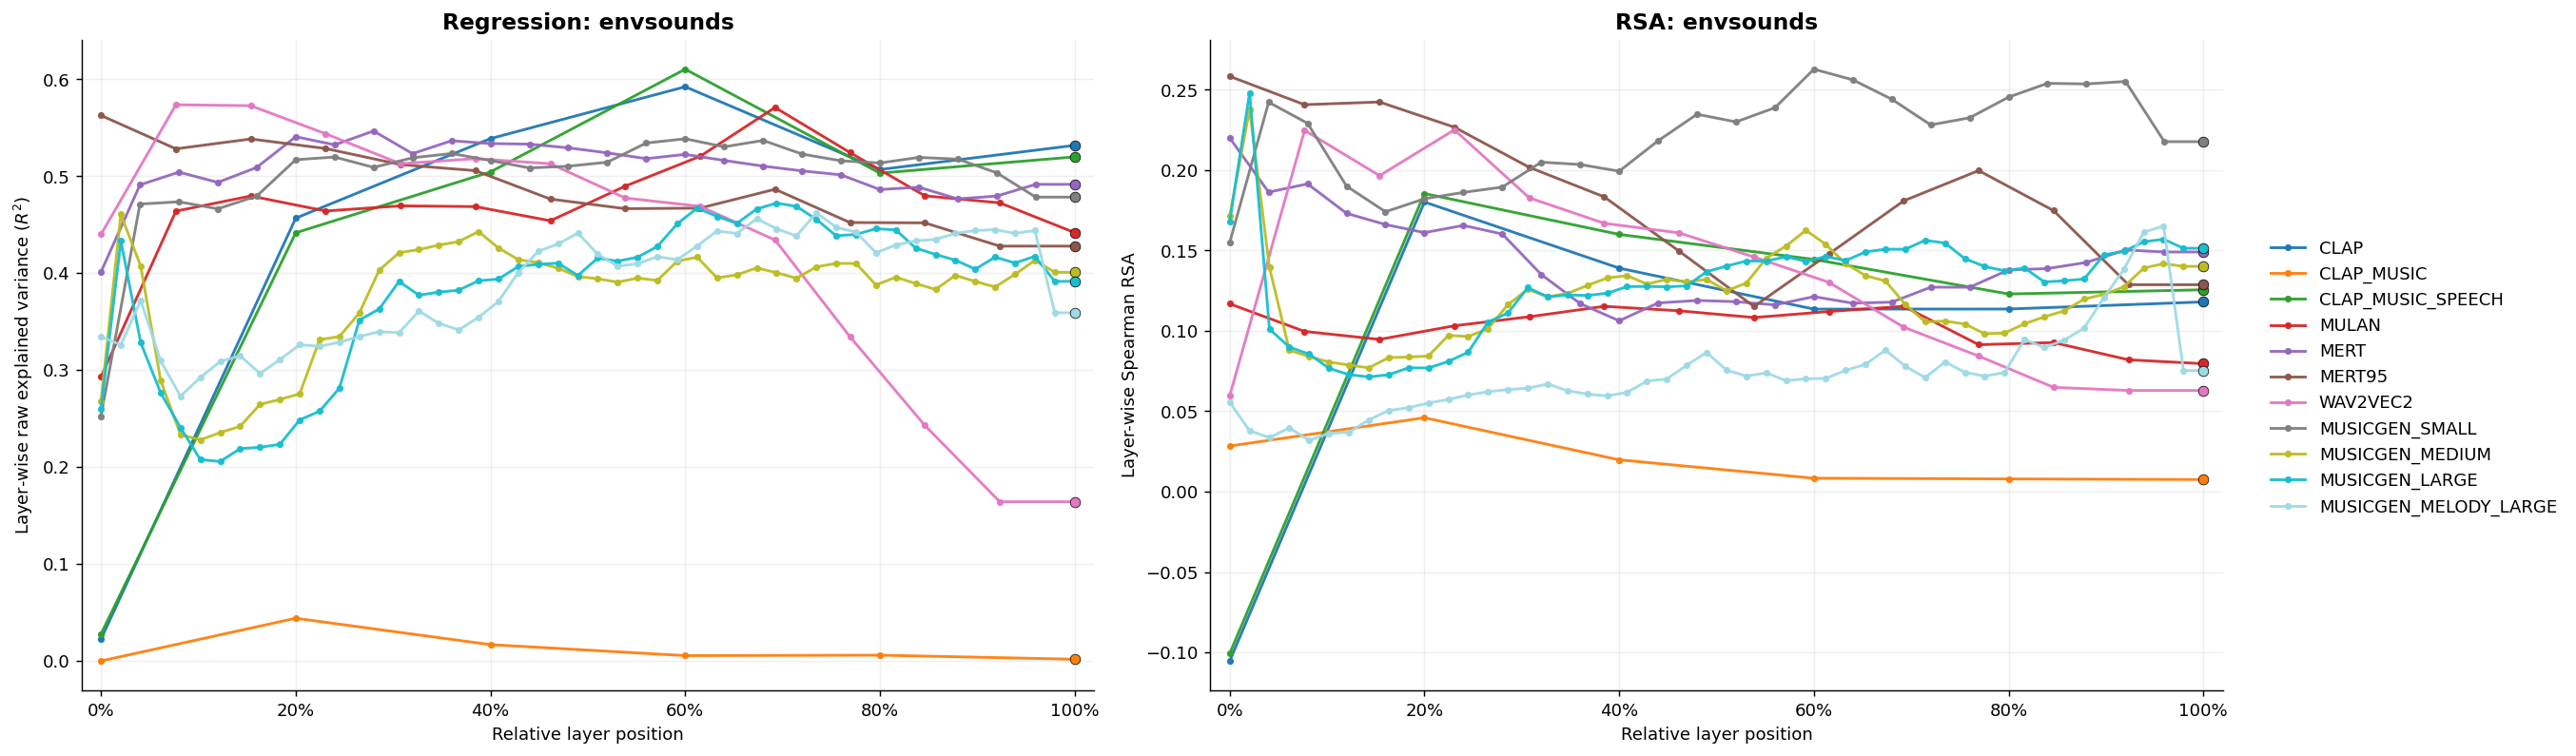

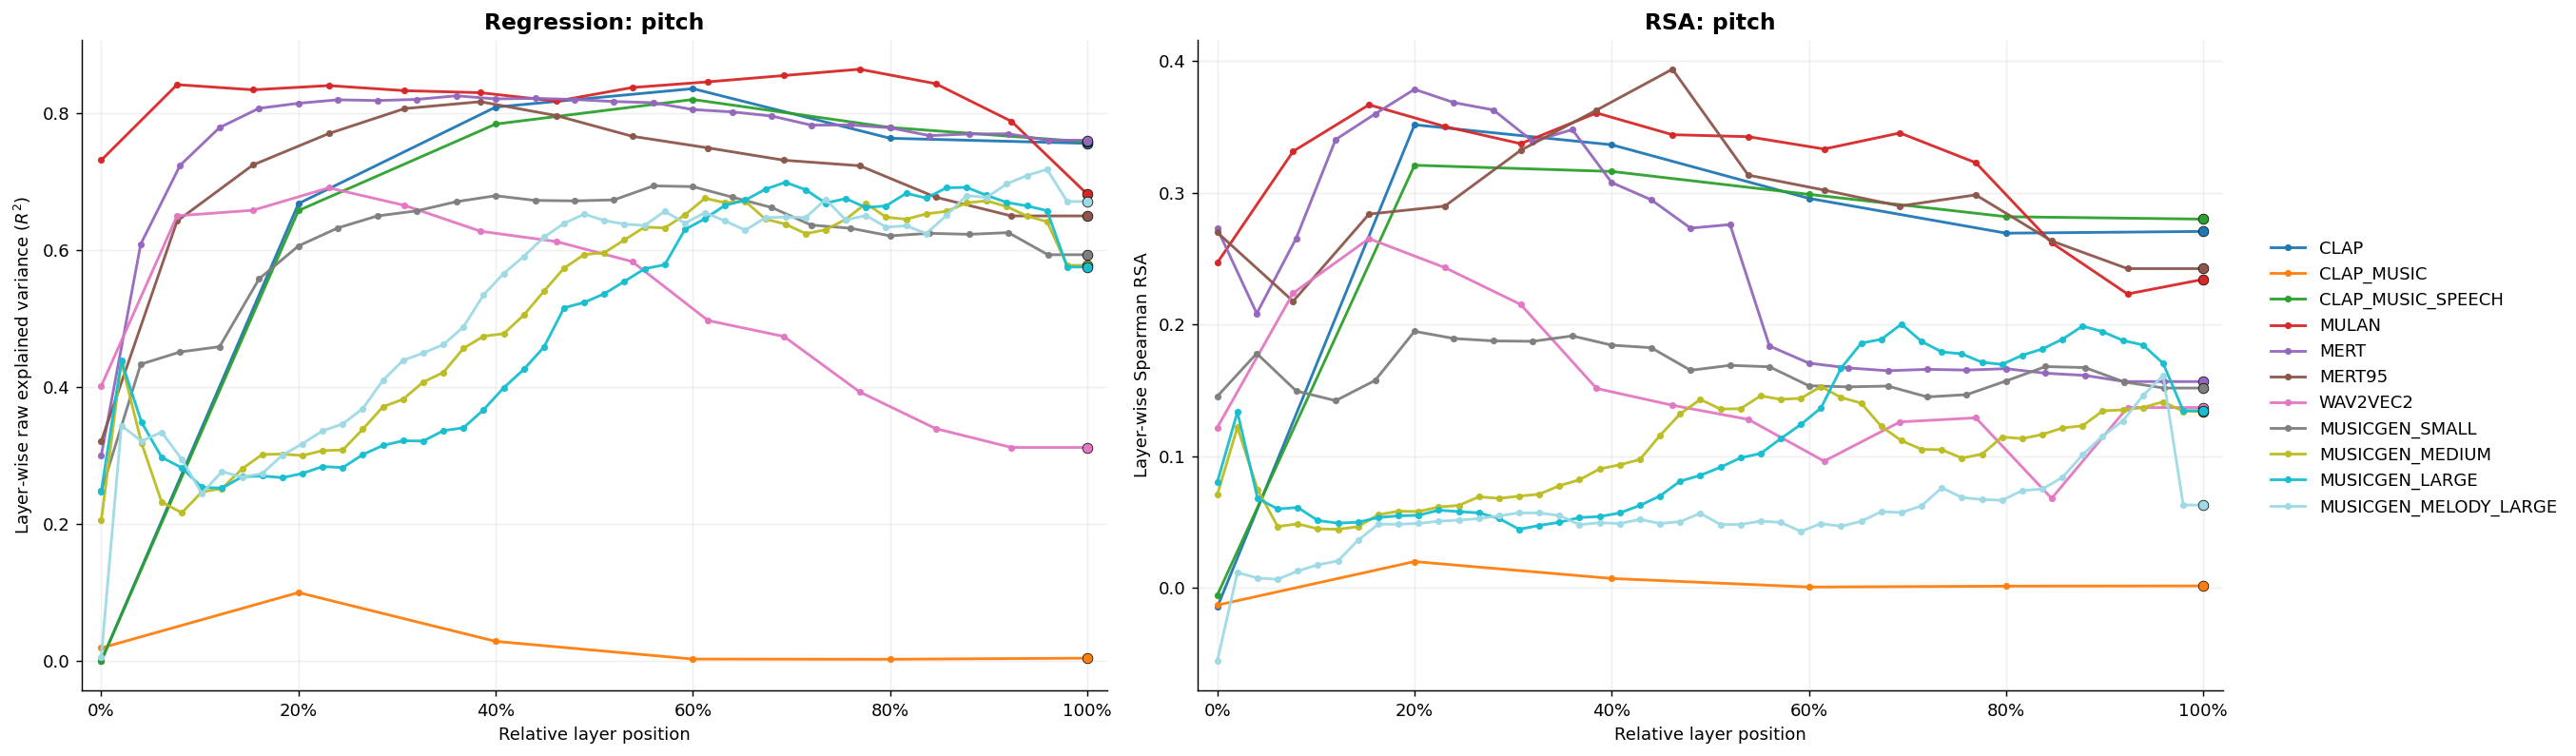

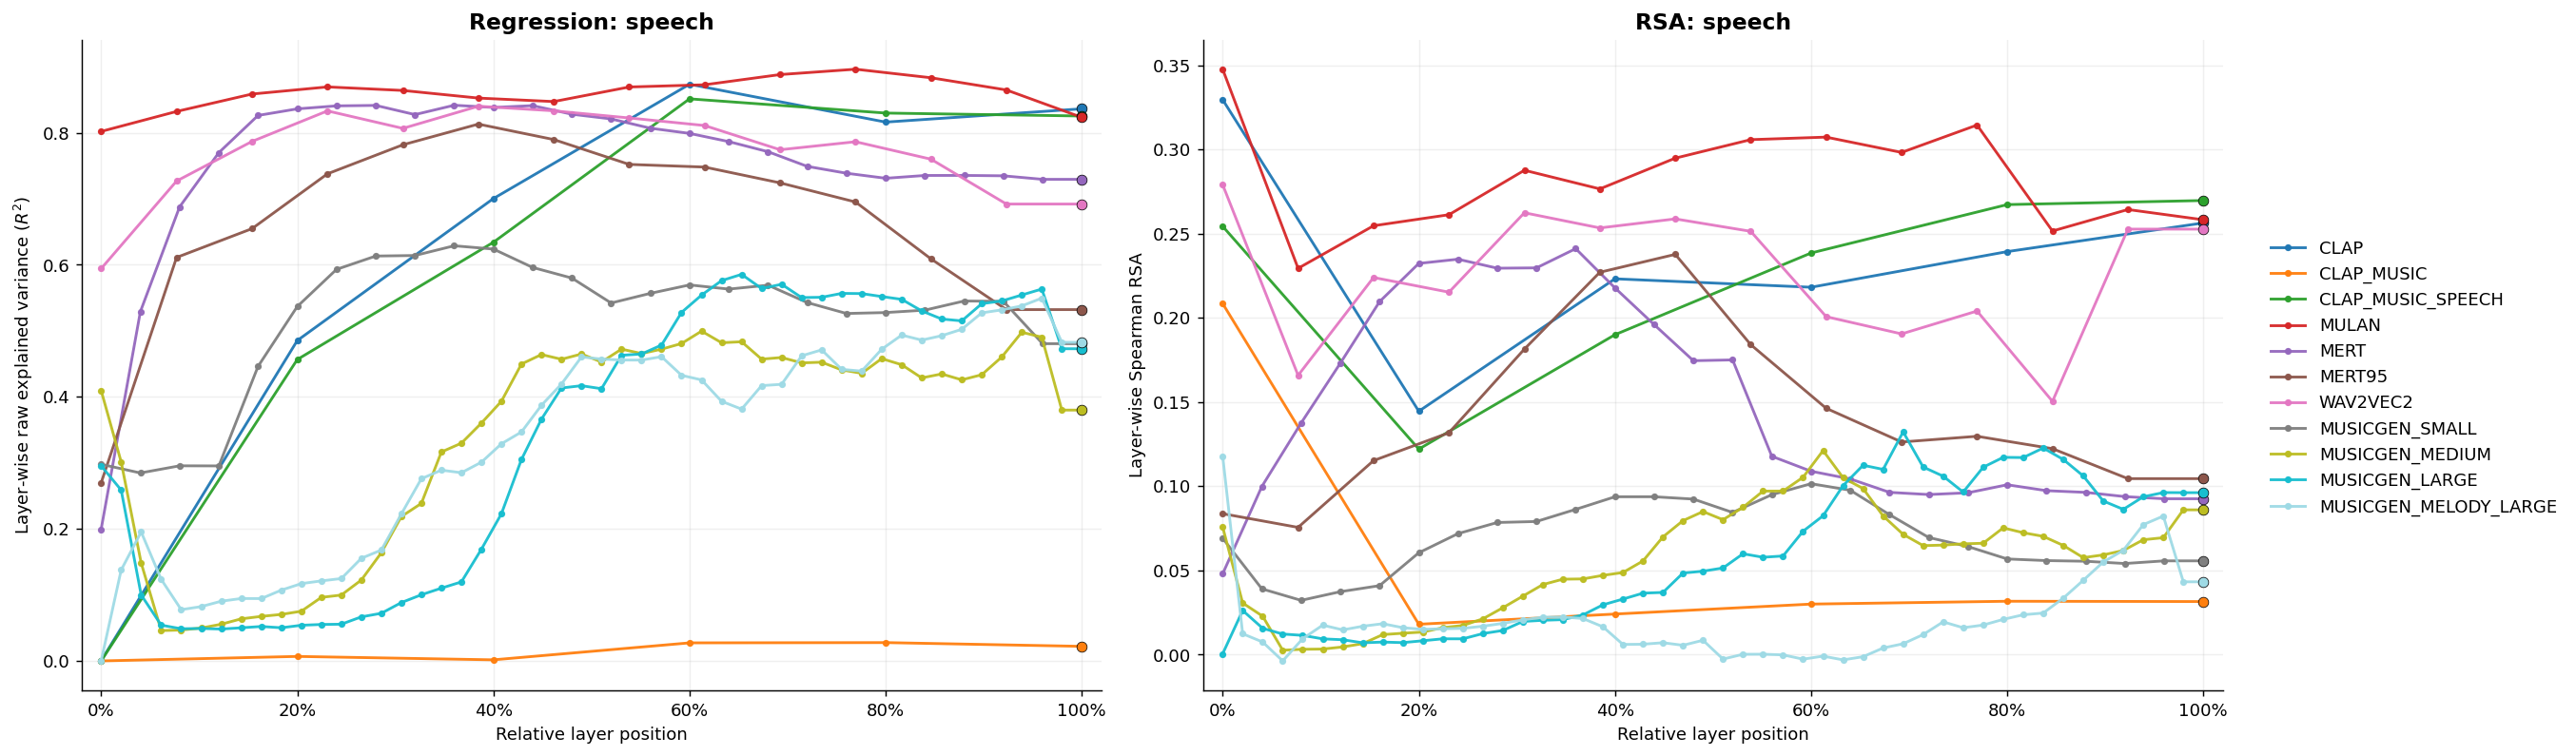

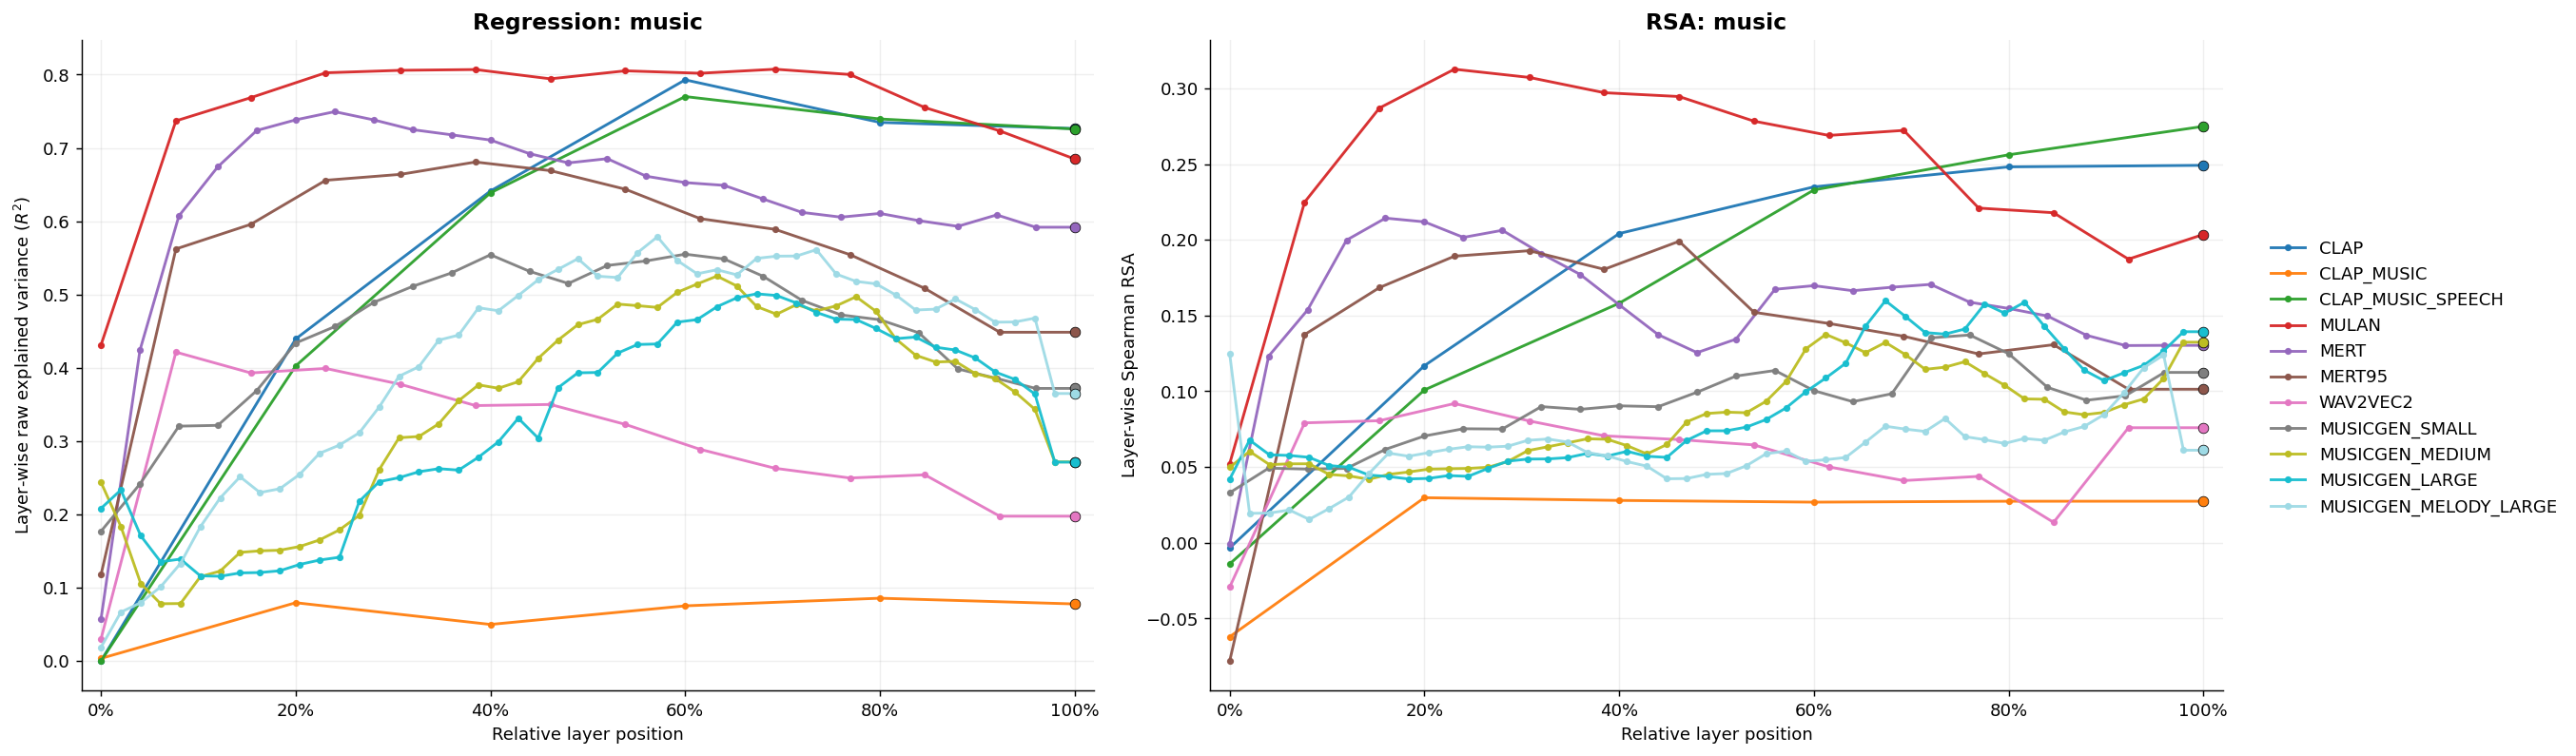

In [6]:
for component_name in COMPONENT_ORDER:
    fig, axes = plot_component_layerwise_all_models(regression_all, rsa_all, component_name=component_name)
    plt.show()
# component_name = 'pitch'  # lowfreq, highfreq, envsounds, pitch, speech, music

# regression_all, rsa_all = refresh_component_summaries()
# fig, axes = plot_component_layerwise_all_models(regression_all, rsa_all, component_name=component_name)
# plt.show()

## 3. One Model Across All Components

Change `model_name` and rerun the cell.

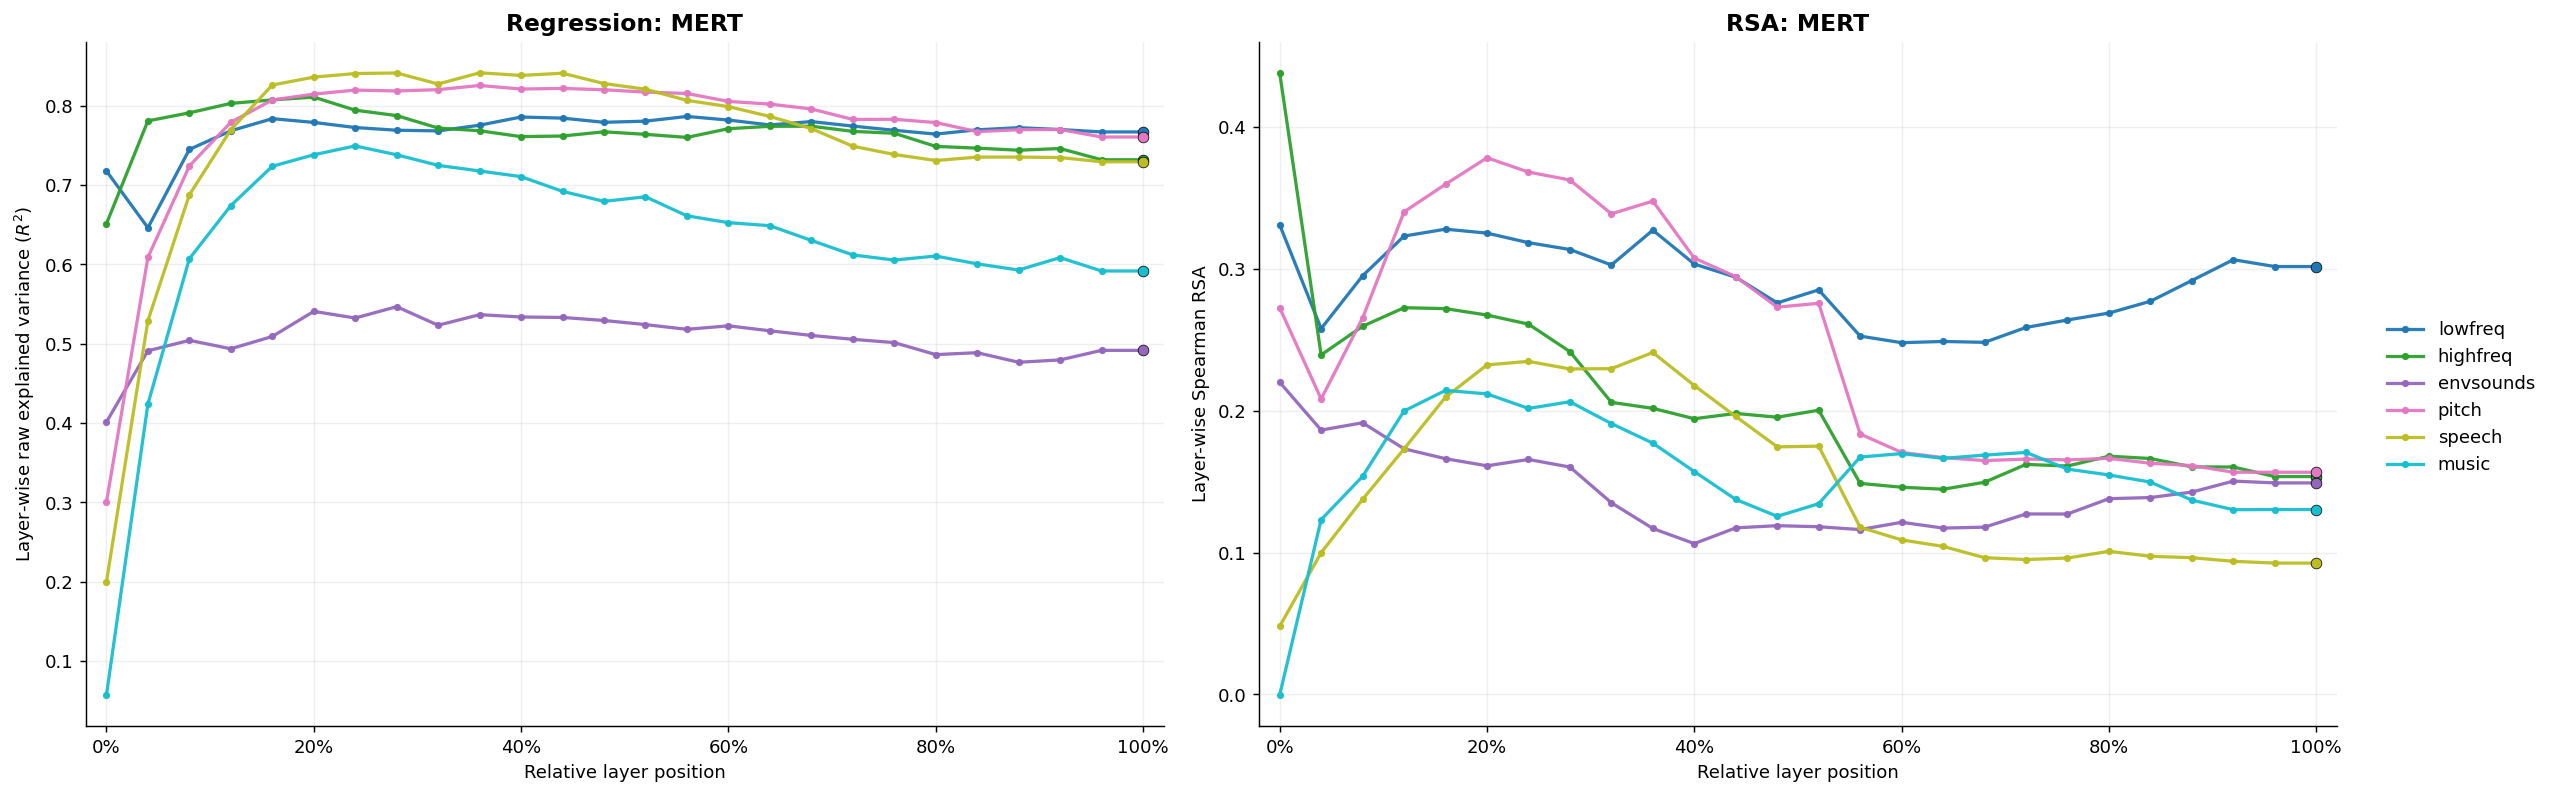

In [4]:
model_name = 'MERT'  # CLAP, CLAP_MUSIC, CLAP_MUSIC_SPEECH, MULAN, MERT, MERT95, WAV2VEC2, MUSICGEN_SMALL, MUSICGEN_MEDIUM, MUSICGEN_LARGE, MUSICGEN_MELODY_LARGE

regression_all, rsa_all = refresh_component_summaries()
fig, axes = plot_model_layerwise_all_components(regression_all, rsa_all, model_name=model_name)
plt.show()